# Pharmacy Closures and Neighborhood Access in Philadelphia
## Spatial assessment and research record
**Emmanuel Amissah Sampson · University of Pennsylvania**  
Urban studies research project · 16 November 2026

**Research status: executed public-data feasibility pilot.** This notebook is the main reproducible record. It does not estimate the historical causal effects of the 2023–2025 Rite Aid closures. Verified operating dates and licensed human-mobility data have not yet been obtained.

The completed calculation removes Rite Aid-labelled entries from a licensed-pharmacy roster. It measures a hypothetical change in straight-line proximity from tract centroids. All results must retain that interpretation.

## 1. Questions and scope
The eventual study asks how pharmacy closures alter destinations, sampled travel patterns, nearby demand and unequal access. Philadelphia pharmacies are the semester-sized case; other retail openings and relocations remain the longer-term agenda.

This public pilot answers three narrower questions:
1. Can we assemble a reproducible spatial analysis from accessible public data?
2. How sensitive is a removal scenario to the definition of the candidate pharmacy inventory?
3. Do baseline access and neighborhood features predict the scenario better than a simple median?

Observed travel mode and emissions changes are not identified by these data.

In [1]:
from pathlib import Path
import sys, json, hashlib
ROOT = Path.cwd()
if not (ROOT / 'config.json').exists():
    ROOT = ROOT.parent
assert (ROOT / 'config.json').exists(), 'Open this notebook inside the project folder'
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
pd.set_option('display.max_columns', 12)


## 2. Provenance and checks
The source manifest records exact URLs, retrieval times, licenses and hashes. Six official bulk ACS tables were streamed and filtered to Philadelphia tract rows. This route does not require a Census API key. Analytical source inputs are kept in `data/raw`; these are included in the project archive but excluded from Git. The optional insurer notice is a contextual reference, excluded from the archive; its source URL remains in the manifest.

If starting from a Git clone, first run `python -m src.download` at the project root. This notebook stops if required analytical inputs are missing or their recorded bytes have changed. The contextual insurer notice is optional and is not used to calculate results.

In [2]:
manifest = json.loads((ROOT / 'data/source_manifest.json').read_text())
for item in manifest:
    path = ROOT / item['local_path']
    if item['id'] == 'closure_notice_2025' and not path.exists():
        print('Optional insurer reference PDF not included; source URL retained in manifest.')
        continue
    assert item['status'] != 'failed', item['id']
    assert path.exists(), f'Missing {path}; run python -m src.download'
    assert hashlib.sha256(path.read_bytes()).hexdigest() == item['sha256'], f'Changed input: {path}'
display(pd.DataFrame(manifest)[['id','status','rows','local_path']].fillna(''))
print('Every required analytical input and available reference matches its recorded SHA-256 hash.')

<ipython-input-2-0390667aa9ad>:10: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  display(pd.DataFrame(manifest)[['id','status','rows','local_path']].fillna(''))


,id,status,rows,local_path
0,pa_pharmacies,downloaded,,data/raw/pa_pharmacies.csv
1,tract_boundaries,downloaded,,data/raw/cb_2022_42_tract_500k.zip
2,nj_county_boundaries,downloaded,,data/raw/cb_2022_us_county_500k.zip
3,closure_notice_2025,downloaded,,data/raw/rite_aid_closure_notice_2025.pdf
4,acs2022_B01003,downloaded,408.0,data/raw/acs2022_b01003_philadelphia.dat
5,acs2022_B19013,downloaded,408.0,data/raw/acs2022_b19013_philadelphia.dat
6,acs2022_B17001,downloaded,408.0,data/raw/acs2022_b17001_philadelphia.dat
7,acs2022_B08201,downloaded,408.0,data/raw/acs2022_b08201_philadelphia.dat
8,acs2022_B03002,downloaded,408.0,data/raw/acs2022_b03002_philadelphia.dat
9,acs2022_B01001,downloaded,408.0,data/raw/acs2022_b01001_philadelphia.dat


Every required analytical input and available reference matches its recorded SHA-256 hash.


## 3. Join geography, demographics and the candidate inventory
ACS estimates describe 2018–2022. We preserve margins of error and turn negative sentinel values into missing values. The denominator for no-vehicle share is households; the poverty denominator is the population for whom poverty status is determined.

Distances use EPSG:26918 (meters). Origins are projected geometric tract centroids, not people's actual homes. PA destinations in a 10 km city buffer are included. Fifty populated tract centers are less than 2 km from New Jersey county geometry and are flagged because NJ pharmacies are missing. All 391 populated tracts remain in the maps and primary proximity results. Only the secondary prediction comparison excludes the 50 flagged tracts, leaving 341. The 2 km rule checks data coverage; it is not a walking threshold and does not correct every cross-border bias.

In [3]:
from src.accessibility import prepare
tracts, pharmacies, quality = prepare()
display(pd.Series(quality, name='count').to_frame())
print('Analysis CRS:', tracts.crs)
display(tracts[['GEOID','population','poverty_rate','no_vehicle_share','age65plus_share','near_nj_2km']].head())

,count
registry_rows,3324
invalid_or_missing_coordinates,0
duplicate_licenses_removed,0
shared_geocode_rows,256
shared_address_rows,49
tracts_total,408
tracts_populated,391
study_buffer_registry_sites,817
rite_aid_labelled_buffer_sites,109
philadelphia_registry_sites,523


Analysis CRS: EPSG:26918


,GEOID,population,poverty_rate,no_vehicle_share,age65plus_share,near_nj_2km
0,42101001500,3251.0,0.061439,0.360319,0.080898,True
1,42101001800,3300.0,0.041212,0.196294,0.092424,True
2,42101002802,5720.0,0.183363,0.229132,0.146154,False
3,42101004001,4029.0,0.208488,0.234973,0.129312,False
4,42101006300,4415.0,0.394558,0.298373,0.066591,False


### What the inventory can and cannot tell us
A license entry is not necessarily an operating community pharmacy. The roster may retain inactive, inpatient-only or nonpublic dispensing locations. Some source geocodes are approximate; several records share addresses or coordinates. A Rite Aid name creates an **unverified closure candidate**, not a dated treatment event.

The code generates `closure_candidates_unverified.csv` with deliberately empty operating dates for manual verification. An announcement date is not automatically a pharmacy closure date.

In [4]:
candidates = pd.read_csv(ROOT / 'data/processed/closure_candidates_unverified.csv', dtype=str)
print(f'{len(candidates)} Rite Aid-labelled candidates in the PA study buffer; none has a verified event date in this run.')
display(candidates[['license_id','name','address','city','date_quality']].head(8))

109 Rite Aid-labelled candidates in the PA study buffer; none has a verified event date in this run.


,license_id,name,address,city,date_quality
0,PP410641L,Rite Aid #11104,1650 Limekiln Pike,Dresher,unverified
1,PP412931L,Rite Aid Pharmacy 1299,2503-05 Welsh Rd,Philadelphia,unverified
2,PP411564L,Rite Aid #11139,6515 Castor Avenue,Philadelphia,unverified
3,PP413411L,Rite Aid Pharmacy #0679,123 S 69Th Street,Upper Darby,unverified
4,PP413272L,Rite Aid Pharmacy 1320,640 Montgomery Ave,Narberth,unverified
5,PP414797L,Rite Aid Pharmacy 3227,3000-02 Reed Street,Philadelphia,unverified
6,PP415262L,Rite Aid #11110,96 North Flowers Mill Rd,Langhorne,unverified
7,PP413047L,Rite Aid #11130,7700 Crittenden Street Suite 101C,Philadelphia,unverified


## 4. The modeled access scenario
For each tract origin i, compare its nearest listed destination before and after removing all Rite Aid-labelled records:

$$\Delta d_i=\min_{j\in P\setminus R}\|x_i-x_j\|-\min_{j\in P}\|x_i-x_j\|.$$

This quantity cannot be negative when the same origin and distance metric are used. It is not an observed journey, and the roster cannot reconstruct actual 2023–2025 operations.

We repeat the calculation using a restricted chain-name inventory. These are **two sensitivity scenarios, not formal lower and upper bounds**.

In [5]:
populated = tracts.loc[tracts.population > 0].copy()
assert (populated.all_listed_delta_m >= -1e-6).all()
comparison = pd.DataFrame({
    'inventory': ['All listed licenses', 'Recognizable chain names'],
    'population_weighted_increment_m': [
        np.average(populated.all_listed_delta_m, weights=populated.population),
        np.average(populated.chain_names_delta_m, weights=populated.population)]})
display(comparison.round(2))
print('These are modeled one-way straight-line changes, not estimated closure effects.')

,inventory,population_weighted_increment_m
0,All listed licenses,32.39
1,Recognizable chain names,282.11


These are modeled one-way straight-line changes, not estimated closure effects.


## 5. Prediction comparison with spatial validation
The target is the scenario distance increment. Predictors use scenario-baseline inventory features and ACS context, excluding the post-removal nearest distance. Models: training-fold median, ridge regression and random forest. Five contiguous coordinate clusters are held out in turn; training origins within 1 km of the held-out region's sample points are removed. Imputation and scaling use training observations only.

This comparison tests whether the baseline features predict variation in a mechanically calculated target. The comparison is secondary to the direct spatial calculation. No claim is made that the model predicts historical closure effects. The roster's timing also prevents treating these features as verified preclosure covariates.

In [6]:
from src.ml import run_ml, FEATURES
OUT = ROOT / 'outputs/public'
OUT.mkdir(parents=True, exist_ok=True)
metrics, predictions = run_ml(tracts, OUT)
display(metrics[['model','n','mae_m','rmse_m','r2']].round(3))
display(pd.DataFrame({'feature': FEATURES}))

/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
found 0 physical cores < 1
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py", line 255, in _count_physical_cores
    raise ValueError(f"found {cpu_count_physical} physical cores < 1")


,model,n,mae_m,rmse_m,r2
0,Median baseline,341,28.272,109.523,-0.071
1,Random forest,341,49.274,105.569,0.005
2,Ridge,341,47.192,104.354,0.027


,feature
0,population_density
1,median_income
2,poverty_rate
3,no_vehicle_share
4,age65plus_share
5,baseline_sites_1km
6,rite_aid_sites_1km
7,all_listed_before_m


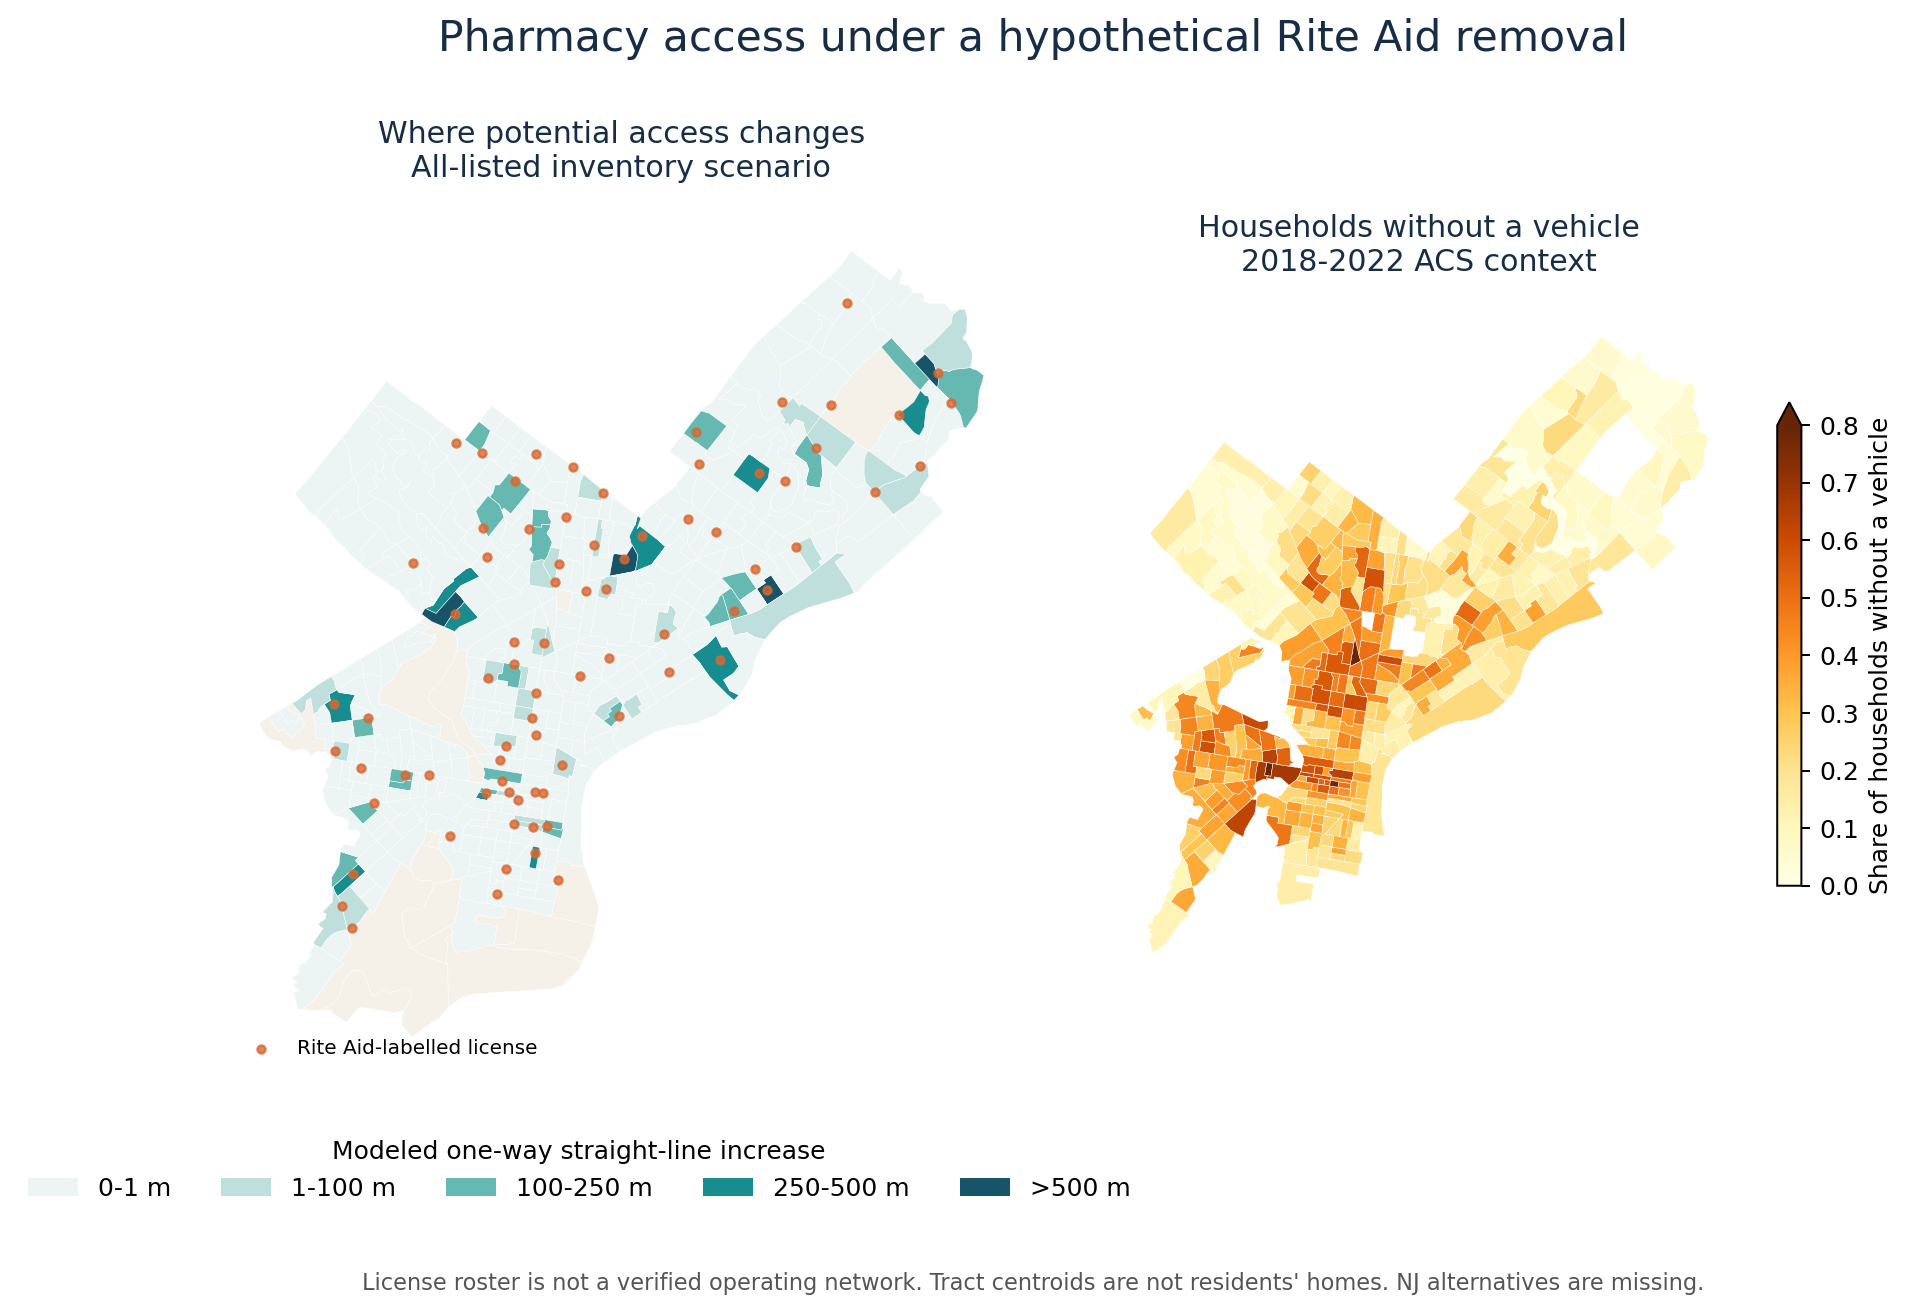

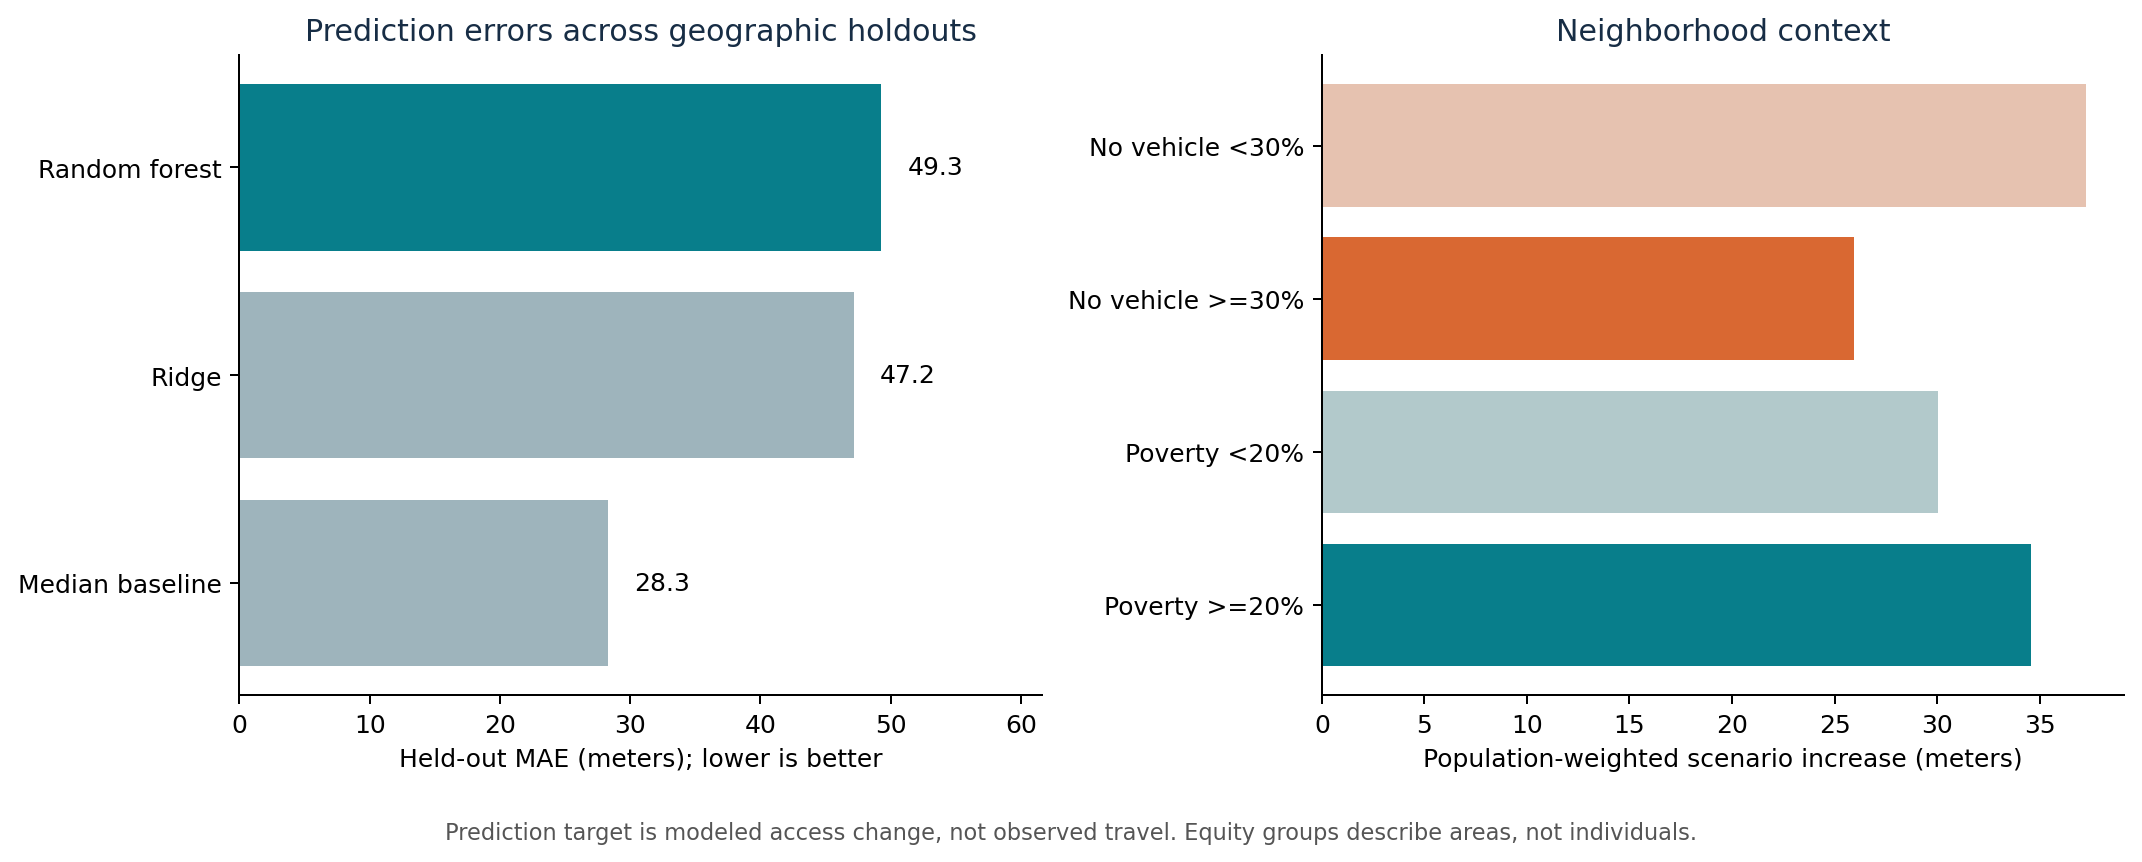

In [7]:
from src.pilot import summarize, figures
summary, equity = summarize(tracts, quality, metrics)
figures(tracts, pharmacies, metrics, equity)
display(Image(filename=str(OUT / 'access_equity_map.png')))
display(Image(filename=str(OUT / 'model_and_equity.png')))

### Interpretation of prediction errors
Lower MAE/RMSE is better; negative R² is possible out of sample. A zero-heavy target rewards the median baseline on MAE. A small improvement in RMSE alongside worse MAE does not establish useful predictive performance. Do not tune on these held-out results and then present the same folds as untouched validation.

The substantial inventory sensitivity is a data-validity warning. Before estimating historical impacts, the operating network needs manual and temporal validation.

In [8]:
ranking = metrics.sort_values('mae_m')
print('Lowest spatially held-out MAE:', ranking.iloc[0]['model'])
rf = metrics.set_index('model').loc['Random forest']
base = metrics.set_index('model').loc['Median baseline']
print(f'Random forest MAE: {rf.mae_m:.1f} m; median baseline MAE: {base.mae_m:.1f} m.')
print('The prediction comparison does not establish a causal effect or useful prediction of real travel.')
display(pd.read_csv(OUT / 'ml_fold_metrics.csv').round(2))

Lowest spatially held-out MAE: Median baseline
Random forest MAE: 49.3 m; median baseline MAE: 28.3 m.
The prediction comparison does not establish a causal effect or useful prediction of real travel.


,model,fold,n_train,n_test,mae_m,rmse_m
0,Median baseline,0,257,67,12.25,49.16
1,Ridge,0,257,67,32.93,51.41
2,Random forest,0,257,67,33.72,51.50
3,Median baseline,1,304,36,61.23,218.96
4,Ridge,1,304,36,71.15,208.12
5,Random forest,1,304,36,77.14,209.48
6,Median baseline,2,216,116,21.21,68.18
7,Ridge,2,216,116,37.02,65.40
8,Random forest,2,216,116,42.02,68.33
9,Median baseline,3,274,58,37.16,115.18


## 6. Equity is an area-level comparison
The table weights tract-origin scenarios by tract population. A second weighting by households without a vehicle is also reported. It cannot reveal the experience of individual residents, and group-specific sample means do not estimate causal heterogeneity. ACS uncertainty is retained in the source but not propagated in these pilot summaries.

In [9]:
display(equity.round(2))
display(pd.Series({
    'Populated tracts': summary['tracts_populated'],
    'Tract centroids with an increase >1 m': summary['populated_tracts_with_any_increase'],
    'Population-weighted scenario increase, m': summary['population_weighted_increment_m'],
    'No-vehicle-household-weighted increase, m': summary['no_vehicle_household_weighted_increment_m'],
    'Nonborder population-weighted increase, m': summary['nonborder_population_weighted_increment_m']
}, name='scenario_summary').round(2))

,group,n_tracts,population,population_weighted_increment_m
0,All populated tracts,391,1593208,32.39
1,Poverty rate at least 20%,192,828525,34.57
2,Poverty rate below 20%,197,764531,30.03
3,No-vehicle share at least 30%,176,682884,25.97
4,No-vehicle share below 30%,212,908907,37.26
5,Age 65+ share at least 20%,82,296501,18.28
6,Non-Hispanic Black share at least 50%,140,556992,21.82
7,Hispanic share at least 50%,24,115692,8.03


Populated tracts                             391.00
Tract centroids with an increase >1 m         67.00
Population-weighted scenario increase, m      32.39
No-vehicle-household-weighted increase, m     27.43
Nonborder population-weighted increase, m     30.34
Name: scenario_summary, dtype: float64

## 7. Conditional emissions scenarios
For 1,000 **hypothetical** person round trips, assume a car share, a route-detour factor and the share of journeys that create additional travel. The EPA's approximately 400 g CO₂ per gasoline-vehicle mile is a tailpipe factor; this is not lifecycle CO₂e or a measured Philadelphia fleet factor.

$$\Delta E=\Delta d\times 2\times r/1609.344\times N\times s_{car}\times s_{additional}\times 400/1000.$$

We assume one traveler per vehicle. There are no observed trips or mode shares in this pilot. A citywide annual emissions total would require unsupported assumptions and is not calculated.

In [10]:
from src.emissions import incremental_co2_kg
emissions = pd.read_csv(OUT / 'emissions_sensitivity.csv')
display(emissions.query('detour_factor == 1.3')[[
    'hypothetical_person_round_trips','car_share','additional_trip_share','additional_tailpipe_co2_kg']].round(2))
print('Scenario only. Changing trip chaining or mode assumptions changes these results.')

,hypothetical_person_round_trips,car_share,additional_trip_share,additional_tailpipe_co2_kg
2,1000,0.25,0.5,2.62
3,1000,0.25,1.0,5.23
8,1000,0.50,0.5,5.23
9,1000,0.50,1.0,10.47
14,1000,0.75,0.5,7.85
15,1000,0.75,1.0,15.70
20,1000,1.00,0.5,10.47
21,1000,1.00,1.0,20.93


Scenario only. Changing trip chaining or mode assumptions changes these results.


## 8. What is required before the causal study can run

| Input | Current status |
|---|---|
| Verified store-specific pharmacy closure intervals | Missing; candidate ledger created |
| Historical operating pharmacy network and replacements | Missing |
| Licensed 2022–2025 origin/POI mobility panel and coverage denominators | Not obtained |
| Historical street/transit routing; NJ alternatives | Not obtained |
| Validated mode information | Not obtained; foot traffic alone is insufficient |

The companion notebook checks for verified inputs before running any empirical contrast. The Python estimator excludes already-treated and flagged spillover controls, but still requires defensible parallel trends and selection assumptions. An optional R extension uses the authors' `did` implementation for a covariate-adjusted analysis; it has not been run.

Read [the full research protocol](../docs/research_protocol.md), [data access instructions](../docs/data_access.md), and [data dictionary](../docs/data_dictionary.md).

## 9. Results and interpretation
The following sections use the same narrative as the website and submission report. Tables and figures above are the executed research record.

## Results

### Access changes are concentrated in a minority of tracts

With all listed destinations eligible, the population-weighted nearest distance rises from 421.2 to 453.6 meters, an increase of 32.4 meters. Sixty-seven tracts (17.1% of populated tracts) have an increase greater than one meter. The other 324 have no calculated increase because a remaining listed destination is already as close or closer than the removed records.

The 67 tracts contain an estimated 281,655 residents. That number describes the population of those tracts; it does not count people observed to have lost access. A citywide average also conceals the larger changes in some individual areas.

### The inventory changes the result substantially

The selected chain-name inventory produces a population-weighted increase of 282.1 meters, about 8.7 times the all-listed result. This difference shows how strongly the calculated loss depends on the alternatives counted. It does not establish which inventory is correct. The all-listed inventory may overstate usable alternatives, while the chain-name restriction excludes legitimate independent pharmacies.

Table 2. Descriptive neighborhood comparisons

| Tract group | Number of tracts | Weighted increase in meters |
| --- | --- | --- |
| All populated tracts | 391 | 32.4 |
| Poverty rate at least 20% | 192 | 34.6 |
| Poverty rate below 20% | 197 | 30.0 |
| Households without a vehicle at least 30% | 176 | 26.0 |
| Households without a vehicle below 30% | 212 | 37.3 |

Higher-poverty tracts have a slightly larger calculated increase than lower-poverty tracts, at 34.6 versus 30.0 meters. The pattern reverses for vehicle availability: tracts where at least 30% of households lack a vehicle have an increase of 26.0 meters, compared with 37.3 meters elsewhere. These results do not support a claim that every disadvantaged group experiences the largest geographic change. They also do not imply that a smaller distance change is easy for residents without a car.

### The simple baseline has the lowest absolute error

Table 3. Prediction errors in held-out geographic areas

| Method | Mean absolute error in meters | Root mean squared error in meters | R squared |
| --- | --- | --- | --- |
| Median baseline | 28.3 | 109.5 | -0.071 |
| Ridge | 47.2 | 104.4 | 0.027 |
| Random forest | 49.3 | 105.6 | 0.005 |

Mean absolute error is the average absolute gap between a prediction and the calculated proximity increase; lower values indicate closer predictions. The median baseline performs best on this measure. Most tracts have no increase, which helps explain its performance. Ridge and random forest have slightly lower root mean squared errors, which place greater weight on large mistakes, but their R squared values are close to zero. These results do not support using the fitted models to forecast real closure impacts.

## Walking driving and emissions

The completed calculation shows reduced proximity under removal. It does not show that residents switched from walking to driving. Holding origins and all other destinations fixed, removing a destination cannot shorten the distance to the nearest remaining option; adding a destination cannot lengthen it. The behavioral and emissions consequences require further evidence.

Table 4. Possible travel responses to location change

| Location change | Possible response | Conditional emissions implication |
| --- | --- | --- |
| Loss of a nearby pharmacy | Longer walking or driving trip; some journeys may switch to a car | Additional gasoline vehicle travel increases tailpipe CO₂ |
| Opening near residents and a usable walking route | A shorter walk or drive may replace a longer car journey | Lower vehicle travel can reduce tailpipe CO₂ |
| Opening that attracts additional car journeys | More trips or diversion to a car-oriented destination | Total vehicle travel and emissions may increase |
| Closure followed by delivery, combined errands or forgone visits | Travel is reorganized or a visit does not occur | The net direction cannot be determined from proximity alone |

EPA guidance connects nearby destinations and transport options with opportunities to walk, cycle or use transit [5]. Applying that mechanism here, a conveniently located opening could support walking, while a closure could make walking less practical. Neither statement is an observed mode result from this project. A reduction in travel because someone cannot obtain essential services should not be treated as an access improvement.

### Conditional emissions calculation

For illustration, the emissions calculation applies the 32.3893-meter population-weighted increase to 1,000 hypothetical person round trips. It assumes one traveler per vehicle and the EPA factor of approximately 400 grams of tailpipe CO₂ per gasoline-vehicle mile [6]. Car share, route detour and the proportion of journeys creating additional travel are varied explicitly.

With half of trips made by car, a route multiplier of 1.3 and all of the modeled extension counted as additional travel, the result is 10.47 kg of additional tailpipe CO₂ per 1,000 person round trips. Across the 24 specified combinations, the result ranges from 2.01 to 25.76 kg. These values are sensitivity calculations, not observed emissions or confidence intervals.

The calculation multiplies the one-way distance increase by two, the route multiplier, the number of person trips, the car share and the additional-travel share, then converts meters to miles and grams to kilograms. Its results are nonnegative by construction because it models added gasoline travel. It therefore cannot establish that closures always increase net emissions. It also omits transit operations, delivery logistics, electricity use and vehicle lifecycle emissions.

## Discussion

The strongest substantive finding is that estimated access loss depends heavily on how the pharmacy network is defined. A modest average increase of 32.4 meters could be interpreted as little consequence if read alone. The concentration in 67 tracts and the much larger result under the chain-name inventory show why that interpretation would be premature. Before debating the magnitude of a historical effect, the analysis needs a verified set of destinations that residents could actually use.

The equity comparisons also require more than a ranking of distances. Higher-poverty areas show a somewhat larger geographic increase, but areas with more households lacking vehicles do not. Vehicle availability can nevertheless change the burden of a given distance. Walking conditions, disability, opening hours and pharmacy eligibility may matter more than a small difference in the neighborhood average. Those dimensions should be measured directly rather than inferred from demographic categories.

The findings establish a reproducible way to identify candidate areas for field checking and test how inventory choices alter the answer. They do not resolve the central behavioral question. Actual changes in visits, transport modes and emissions remain empirical questions, and the study’s next stage must distinguish displacement to other pharmacies from reduced access to pharmacy services overall.

## Recommendations

First, verify the operating pharmacy inventory before using these results for resource allocation. Audit the 109 Rite Aid-labelled buffer records, confirm public access and operating dates, retain independent pharmacies, and add New Jersey alternatives. The 67 tracts with a calculated increase are a practical starting list for investigation, not a validated list of neighborhoods with unmet need.

Second, evaluate access through usable routes and services. A local assessment should combine walking and transit travel times with opening hours, insurance acceptance, prescription capacity and replacement arrangements. Tracts with many households without vehicles deserve attention even when their straight-line increase is small.

Third, assess proposed openings and closure responses against existing travel patterns. A nearby pharmacy with safe pedestrian access may reduce the need for longer car journeys. A car-oriented opening may attract additional vehicle travel. Planning decisions should compare these possibilities using routed access and observed journeys rather than assuming that every opening lowers emissions.

Finally, collect the evidence needed for a historical evaluation before making causal or carbon claims. Track total pharmacy visitation as well as receiving-store gains, preserve mobility-panel coverage information, and assess who is missing from the sample. Prediction models should be reconsidered only after the inventory and outcomes are improved; the current models offer no advantage over the median baseline on average absolute error.

## Limitations

The main limitation is temporal validity. The available license roster is a snapshot that may include inactive, nonretail or nonpublic locations. Removing all Rite Aid-labelled entries at once does not reproduce the sequence of 2023–2025 closures. The study consequently estimates a spatial scenario, not a historical treatment effect.

Geographic measurement is also incomplete. Geometric tract centers conceal variation within neighborhoods, straight lines omit route barriers, and some pharmacy coordinates are approximate. New Jersey alternatives are missing from every main result. Excluding 50 nearby origins from the prediction comparison does not remove that limitation from the descriptive analysis.

The ACS estimates describe areas during 2018–2022. Margins of error are retained in the inputs but are not propagated into the reported comparisons. Missing covariates change subgroup sample sizes, and neighborhood characteristics cannot identify an individual resident’s experience. The study does not measure pharmacy capacity, service compatibility, disability or unmet medication need.

No observed trip histories, validated mode shares or local emissions measurements are available. The emissions exercise assumes additional gasoline vehicle travel and does not estimate net transport emissions. Future device-based data may underrepresent older, lower-income or less digitally visible residents. Even with those data, closure selection and spillovers may limit the credibility of causal comparisons.

## Conclusion

The completed study shows that removing Rite Aid-labelled records increases modeled nearest-pharmacy distance in a minority of Philadelphia tracts and that the magnitude depends strongly on the destination inventory. It also shows that neighborhood disadvantage does not map uniformly onto the calculated distance change. The project delivers a reproducible spatial assessment, documented public data, an executed notebook and a design for extending the analysis to historical outcomes.

Closures can make walking less practical and increase emissions when they create additional car travel. Well-located openings can support walking and reduce vehicle travel when they replace longer journeys. The present evidence does not establish that either behavioral change occurred in Philadelphia. Verifying operating destinations and measuring actual travel are the necessary next steps.


## References

1. Pennsylvania Department of State and Department of Health. Find Naloxone at a Pharmacy Near Me Current Statewide. Dataset ysdx-4vmi; portal update July 1, 2025. [Source](https://data.pa.gov/Opioid-Related/Find-Naloxone-at-a-Pharmacy-Near-Me-Current-Statew/ysdx-4vmi/about_data)

2. U.S. Census Bureau. 2022 American Community Survey five-year Summary File. Tables B01001, B01003, B03002, B08201, B17001 and B19013; estimates cover 2018–2022. [Source](https://www.census.gov/programs-surveys/acs/data/summary-file.2022.html)

3. U.S. Census Bureau. 2022 Cartographic Boundary Files. Pennsylvania census tracts and United States counties at 1:500,000 scale. [Source](https://www.census.gov/geographies/mapping-files/time-series/geo/cartographic-boundary.html)

4. Philadelphia City Council. Resolution 240071. Pharmacy closures and access concerns. [Source](https://phila.legistar.com/LegislationDetail.aspx?ID=6503447&GUID=E7438EA1-5E3E-460A-9902-FCDE7D12D48B&FullText=1)

5. U.S. Environmental Protection Agency. Smart Growth and Transportation. Access to destinations and transportation choices. [Source](https://www.epa.gov/smartgrowth/smart-growth-and-transportation)

6. U.S. Environmental Protection Agency. Greenhouse Gas Emissions from a Typical Passenger Vehicle. Approximately 400 grams of tailpipe CO₂ per gasoline-vehicle mile. [Source](https://www.epa.gov/greenvehicles/greenhouse-gas-emissions-typical-passenger-vehicle)

7. Callaway, B., and Sant’Anna, P. H. C. (2021). Difference-in-Differences with Multiple Time Periods. Journal of Econometrics, 225(2), 200–230. [Source](https://doi.org/10.1016/j.jeconom.2020.12.001)

8. Butts, K. Difference-in-Differences Estimation with Spatial Spillovers. Working paper, arXiv:2105.03737. [Source](https://arxiv.org/abs/2105.03737)

9. Penn Libraries (2025). Penn Data Access Unlocked via Dewey Platform. May 21. [Source](https://www.library.upenn.edu/lippincott/datapoints/data-access-dewey-2025)

10. AmeriHealth Caritas Pennsylvania and Community HealthChoices (2025). Rite Aid pharmacy closure notice. June 5. Contextual evidence of closures and prescription transfers; not a store-specific event ledger. [Source](https://www.amerihealthcaritaschc.com/content/dam/amerihealth-caritas/acpchc/pdf/provider/resources/communications/2025/20250605-rite-aid-pharmacy-closure-notice.pdf.coredownload.inline.pdf)

See [additional source notes](../docs/references.md) for mobility and software documentation.